In [1]:
!pip install -q scikit-learn seaborn matplotlib torchvision torch


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
from google.colab import files
if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Please upload your kaggle.json credential configuration dictionary token:")
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

Please upload your kaggle.json credential configuration dictionary token:


Saving kaggle.json to kaggle.json


In [5]:
if not os.path.exists('new-plant-diseases-dataset.zip'):
    !kaggle datasets download -d vipoooool/new-plant-diseases-dataset
    !unzip -q new-plant-diseases-dataset.zip
    print("Dataset extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:32<00:00, 87.9MB/s]

Dataset extracted successfully!


In [6]:
DATASET_DIR = "New Plant Diseases Dataset/New Plant Diseases Dataset"
TRAIN_DIR = "/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train"
VALID_DIR = "/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid"

In [7]:
print("Train path:", TRAIN_DIR)
print("Valid path:", VALID_DIR)

Train path: /content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Valid path: /content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid


In [8]:
for root, dirs, files in os.walk("/content"):
  if "train" in dirs and "New Plant Diseases Dataset" in root:
    print(os.path.join(root, "train"))

/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train


In [ ]:
train_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomRotation(20),
    transforms.RandomResizedCrop((224,224), scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
val_dataset = datasets.ImageFolder(VALID_DIR, transform=val_transforms)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

NUM_CLASSES = len(train_dataset.classes)
class_names = train_dataset.classes
print(f"Total Classes: {NUM_CLASSES}")

# Exporting classes for streamlit
with open("classes.txt", "w") as f:
    for name in class_names:
        f.write(f"{name}\n")

Total Classes: 38


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


**BASELINE CNN**

In [10]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=38):
        super(BaselineCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.25),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_base = optim.Adam(baseline_model.parameters(), lr=1e-4)

In [ ]:
epochs = 10
scaler = torch.cuda.amp.GradScaler()

print("Baseline CNN Model")
for epoch in range(epochs):
    baseline_model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_base.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = baseline_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer_base)
        scaler.update()
        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{epochs} Training Loss: {epoch_loss:.4f}")

torch.save(baseline_model.state_dict(), "baseline_cnn_model.pth")
print("Baseline CNN saved successfully.")

Baseline CNN Model


/tmp/ipykernel_6130/2646614139.py:2: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() # Keeps optimization efficient and fast on T4
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_6130/2646614139.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/10 Training Loss: 2.2308
Epoch 2/10 Training Loss: 1.4342
Epoch 3/10 Training Loss: 1.1884
Epoch 4/10 Training Loss: 1.0280
Epoch 5/10 Training Loss: 0.9319
Epoch 6/10 Training Loss: 0.8499
Epoch 7/10 Training Loss: 0.7891
Epoch 8/10 Training Loss: 0.7333
Epoch 9/10 Training Loss: 0.6868
Epoch 10/10 Training Loss: 0.6489
Baseline CNN saved successfully.


**BASELINE CNN MODEL EVALUATION**

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



Baseline CNN Evaluation Metrics
Accuracy:  0.8997
Precision: 0.9031
Recall:    0.8997
F1-Score:  0.8980

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.79      0.84       504
           1       0.84      0.97      0.90       497
           2       0.97      0.90      0.93       440
           3       0.96      0.82      0.88       502
           4       0.92      0.96      0.94       454
           5       0.97      0.94      0.96       421
           6       0.95      0.98      0.97       456
           7       0.90      0.88      0.89       410
           8       1.00      0.98      0.99       477
           9       0.93      0.92      0.92       477
          10       0.99      0.95      0.97       465
          11       0.91      0.77      0.83       472
          12       0.81      0.97      0.88       480
          13       0.94      0.99      0.96       430
          14       0.89      0.97      0.93       423
      

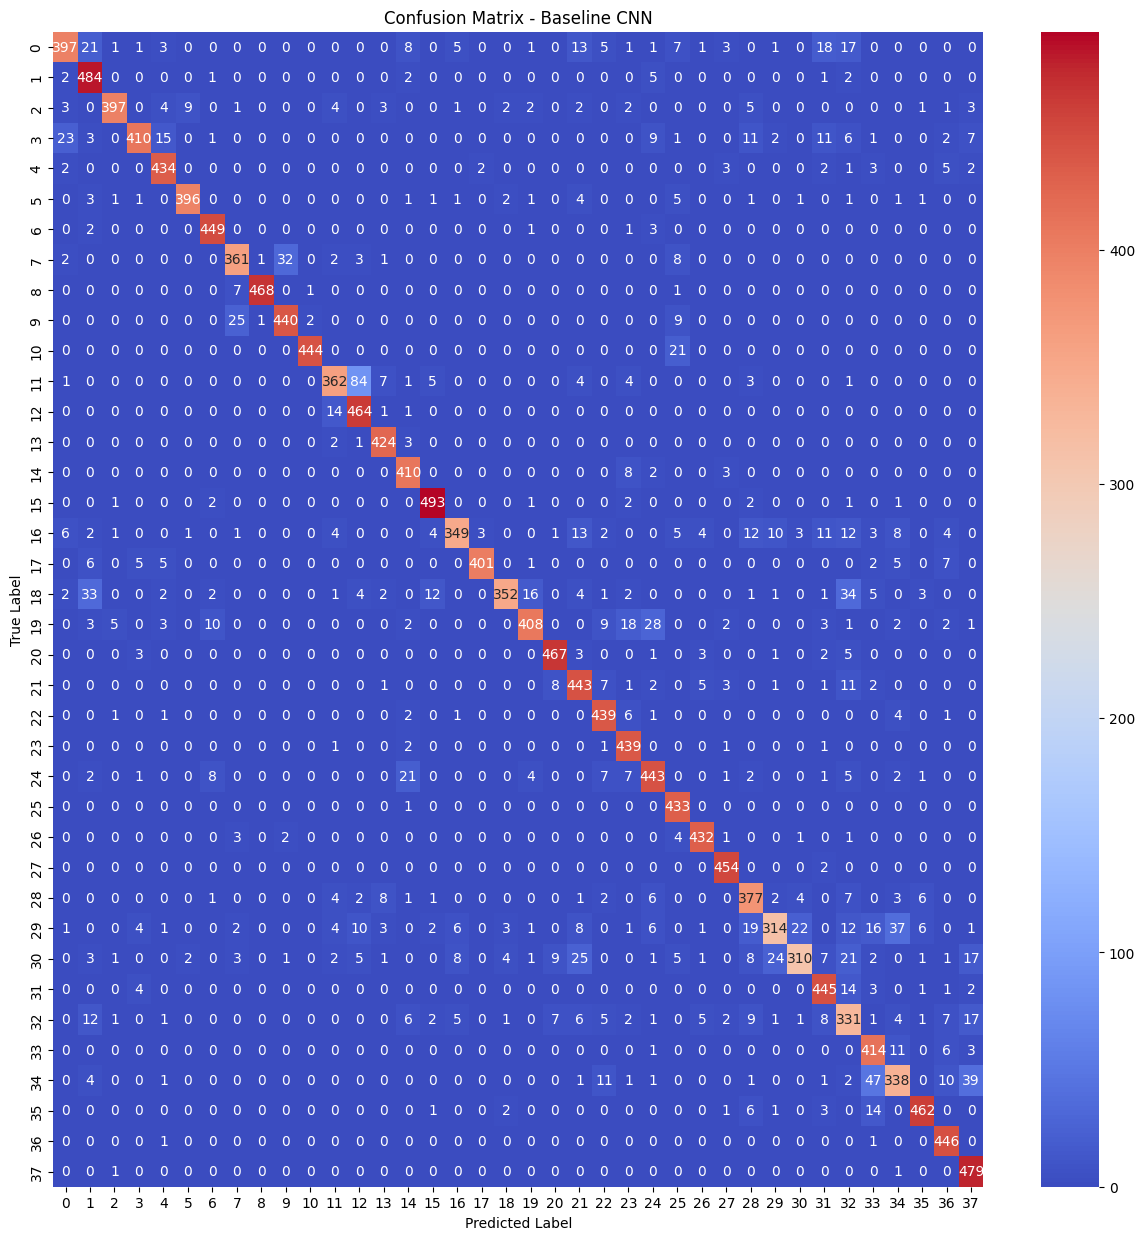

In [ ]:
baseline_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader: 
        images, labels = images.to(device), labels.to(device)
        outputs = baseline_model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Converting lists to numpy array
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print("\nBaseline CNN Evaluation Metrics")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 15))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm')
plt.title('Confusion Matrix - Baseline CNN')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

**RESNET50 MODEL**

In [ ]:
resnet_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Freeze base features
for param in resnet_model.parameters():
    param.requires_grad = False


num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Sequential(
    nn.Linear(num_ftrs, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, NUM_CLASSES)
)
resnet_model = resnet_model.to(device)
optimizer_resnet = optim.Adam(resnet_model.fc.parameters(), lr=1e-4)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


In [ ]:
for epoch in range(epochs):
    resnet_model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_resnet.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = resnet_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer_resnet)
        scaler.update()
        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{epochs} -> Fine Tuning Evaluation Loss: {epoch_loss:.4f}")

torch.save(resnet_model.state_dict(), "resnet50_plant_model.pth")
print("ResNet50 model weights dictionary configurations written to disk.")

/tmp/ipykernel_1851/2115697211.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/10 -> Fine Tuning Evaluation Loss: 1.9000
Epoch 2/10 -> Fine Tuning Evaluation Loss: 0.7383
Epoch 3/10 -> Fine Tuning Evaluation Loss: 0.5030
Epoch 4/10 -> Fine Tuning Evaluation Loss: 0.3975
Epoch 5/10 -> Fine Tuning Evaluation Loss: 0.3366
Epoch 6/10 -> Fine Tuning Evaluation Loss: 0.2936
Epoch 7/10 -> Fine Tuning Evaluation Loss: 0.2636
Epoch 8/10 -> Fine Tuning Evaluation Loss: 0.2399
Epoch 9/10 -> Fine Tuning Evaluation Loss: 0.2220
Epoch 10/10 -> Fine Tuning Evaluation Loss: 0.2115
ResNet50 model weights dictionary configurations written to disk.


In [ ]:
resnet_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = resnet_model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.97      0.95      0.96       504
                                 Apple___Black_rot       0.97      0.99      0.98       497
                          Apple___Cedar_apple_rust       0.98      0.97      0.98       440
                                   Apple___healthy       0.98      0.96      0.97       502
                               Blueberry___healthy       0.96      0.99      0.98       454
          Cherry_(including_sour)___Powdery_mildew       1.00      0.96      0.98       421
                 Cherry_(including_sour)___healthy       0.99      1.00      0.99       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.97      0.82      0.89       410
                       Corn_(maize)___Common_rust_       0.99      1.00      0.99       477
               Corn_(maize)___Northern_Leaf_Blight       0.87      0.98      0.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


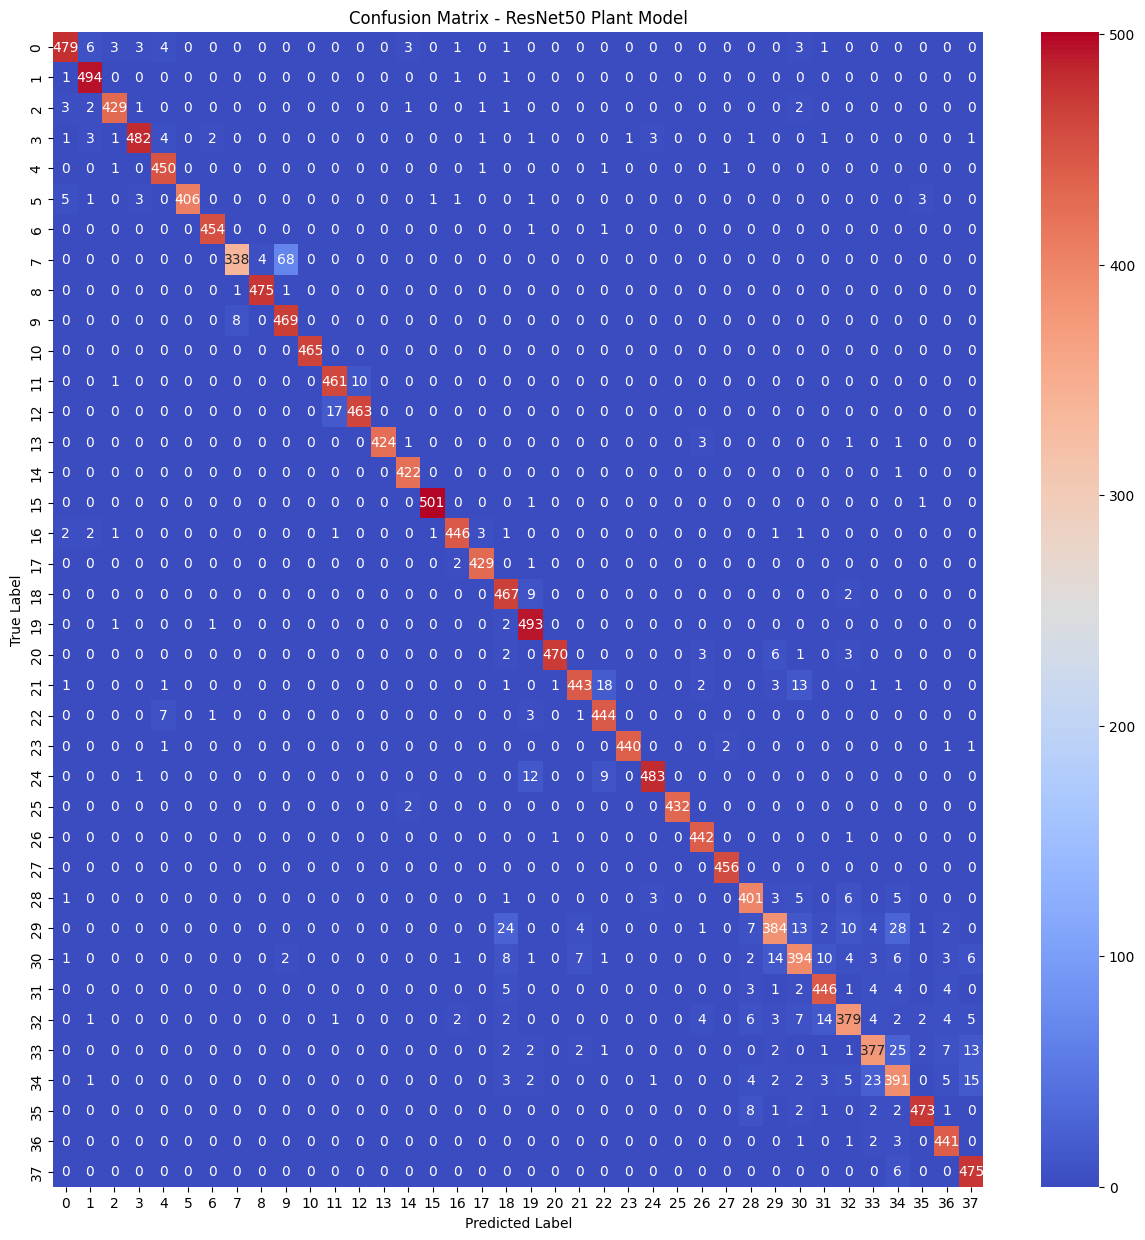

In [ ]:

resnet_model = models.resnet50(weights=None)

num_features = resnet_model.fc.in_features
num_classes = 38

resnet_model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, num_classes)
)
resnet_model = resnet_model.to(device)


model_path = "resnet50_plant_model.pth"
resnet_model.load_state_dict(torch.load(model_path, map_location=device))


resnet_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = resnet_model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert lists to numpy array
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

#Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 15))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm')
plt.title('Confusion Matrix - ResNet50 Plant Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

**ACCURACY COMPARISON BETWEEN THE BASELINE CNN AND RESNET50**

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(0.0, 105.0)

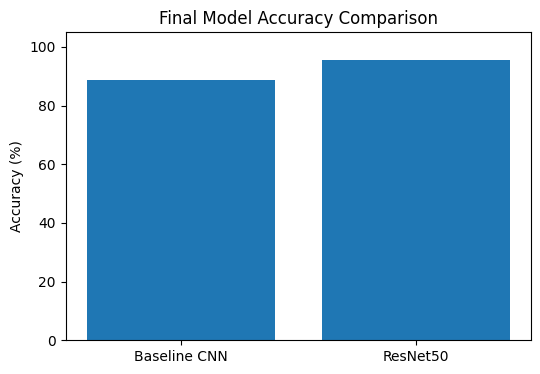

In [ ]:
def calculate_accuracy(model, data_loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return (correct / total) * 100

acc_base = calculate_accuracy(baseline_model, val_loader)

acc_resnet = calculate_accuracy(resnet_model, val_loader)


plt.figure(figsize=(6, 4))
models = ['Baseline CNN', 'ResNet50']
scores = [acc_base, acc_resnet]

bars = plt.bar(models, scores)
plt.ylabel('Accuracy (%)')
plt.title('Final Model Accuracy Comparison')
plt.ylim(0, 105)
